In [1]:
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin
import matplotlib.pyplot as plt
import time

In [24]:
class LinBase(BaseEstimator, ClassifierMixin):
    def __init__(self, coef=None, intercept=None, class_labels=None):
        self.coef_ = coef
        self.intercept_ = intercept
        self.class_labels_ = class_labels
 
    def margin(self, X, y):
        m = y * (X.dot(self.coef_) + self.intercept_)
        return np.min(m), m
 
    def decision_function(self, X):
        a, b = self.margin(X, np.ones(X.shape[0]))
        return b
 
    def predict_proba(self, X):
        a, b = self.margin(X, np.ones((X.shape[0],)))
        return np.array([1 - 1 / (1 + np.exp(-b)), 1 / (1 + np.exp(-b))]).T
 
    def predict(self, X):
        results = np.sign(X.dot(self.coef_) + self.intercept_)
        results_mapped = self.class_labels_[1 * (results > 0)]
        return results_mapped
 
    def get_params(self, deep=True):
        pass
 
    def set_params(self, **parameters):
        for parameter, value in parameters.items():
            setattr(self, parameter, value)
        return self
 
    def __str__(self):
        return "{} [ w={}, b={} ] ".format(self.__class__.__name__, self .coef_ , self . intercept_)

In [25]:
class Perceptron(LinBase):
    def __init__(self, break_time=1, **kwargs):
        super(Perceptron, self).__init__(**kwargs)
        self.break_time_ = break_time
 
    def fit(self, X, y):
        m, n = X.shape
        self.class_labels_ = np.unique(y)
        if self.coef_ is not None:
            w = self.coef_
        else:
            w = np.zeros(n)
 
        if self.intercept_ is not None:
            b = self.intercept_
        else:
            b = 0
        i = 0
        k = 0
        t1 = time.time()
        t2 = time.time()
        while k < m and t2-t1 < 3600:
            if(y[i] * (w.dot(X[i, :]) + b)) <= 0:
                w = w + X[i, :] * y[i]
                b = b + y[i]
                k = 0
            else:
                k += 1
            i = (i + 1) % m
            t2 = time.time()
            if t2 - t1 > self.break_time_:
                print("Przekroczony czas!")
                break
                
        self.coef_ = w
        self.intercept_ = b
 
def plotClass(X, y, clf=None, marker=["ro", "k+"], n=50):
    uy = np.unique(y)
    for i, u in enumerate(uy):
        plt.plot(X[y == u, 0], X[y == u, 1], marker[i], label=str(u))
 
    if clf is not None:
        X1, X2 = np.meshgrid(np.linspace(np.min(X[:,0]),np.max(X[:,0]),n), np.linspace(np.min(X[:,1]),np.max(X[:,1]),n))
        XX = np.array([X1.ravel(), X2.ravel()]).T
        yy = clf.predict(XX)
        yy = np.reshape(yy, X1.shape)
        plt.contour(X1,X2, yy, [0.5])
    else:
        pass
    plt.show()

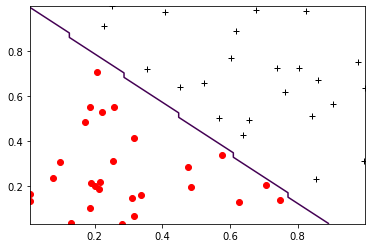

[2.19652499 1.99604014] -2


In [28]:
if __name__ == "__main__":
    m, n = 50, 2
    X = np.random.rand(m, n)
    y = (X.dot([1, 1]) > 1) * 2 - 1
    for i, clf in enumerate([Perceptron()]):
        clf.fit(X, y)
        plotClass(X, y, clf)
        print(clf.coef_, clf.intercept_)